In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_bvp

k = 1.0
A, B = 2, 2
u = lambda t,x,y: -t*y
v = lambda t,x,y: 0.0
u_x = lambda t,x,y: 0.0
u_y = lambda t,x,y: -t
v_x = lambda t,x,y: 0.0
v_y = lambda t,x,y: 0.0

In [2]:
""""
as defined in zermelo's paper
"""

def dphi_dt(t, x, y, phi):
    return (v_x(t, x, y)*np.sin(phi)**2
            + (u_x(t, x, y) - v_y(t, x, y))*np.sin(phi)*np.cos(phi)
            - u_y(t, x, y)*np.cos(phi)**2)
"""
rescaling parameters
w = (x,y,phi), p = vector of unknown parameters (here T)
"""

def rhs(s, w, p):
    x, y, phi = w
    T = p[0]
    t = T*s
    return np.vstack([T*(u(t, x, y) + k*np.cos(phi)),
                      T*(v(t, x, y) + k*np.sin(phi)),
                      T*dphi_dt(t, x, y, phi)])

"""
boundary conditions
where wa = state, wb = state at s=1. p is vector of unknown parameters (here T)
"""
def bc(wa, wb, p):
    return np.array([wa[0], wa[1], wb[0] - A, wb[1] - B])

"""
solve_bvp needs guess for entire trajectory
"""
s = np.linspace(0, 1, 50)
#T0 = np.hypot(A, B)/k
T0 = 6.0
w0 = np.vstack([A*s, B*s, np.arctan2(B, A)*np.ones_like(s)])

sol = solve_bvp(rhs, bc, s, w0, p=[T0], tol=1e-8)
"""
solution:
sol.p[0] for T, sol.y for (x,y,phi) and sol.sol(s) for evaluation (s in [0,1])"""

print(sol.y)
print('final time:', sol.p[0])

[[-1.48897354e-17  3.60135365e-02  7.27962977e-02 ...  3.26747527e+00
   2.63336617e+00  2.00000000e+00]
 [-4.72387588e-17 -1.68201047e-02 -3.09944763e-02 ...  2.00487946e+00
   2.00298118e+00  2.00000000e+00]
 [-1.36060681e+01 -1.36060793e+01 -1.36060963e+01 ... -1.99673160e+00
  -1.97042500e+00 -1.94230624e+00]]
final time: 18.281286526173954


converged: False | T = 18.281287 | phi(0) = -779.570 deg | mesh nodes = 442


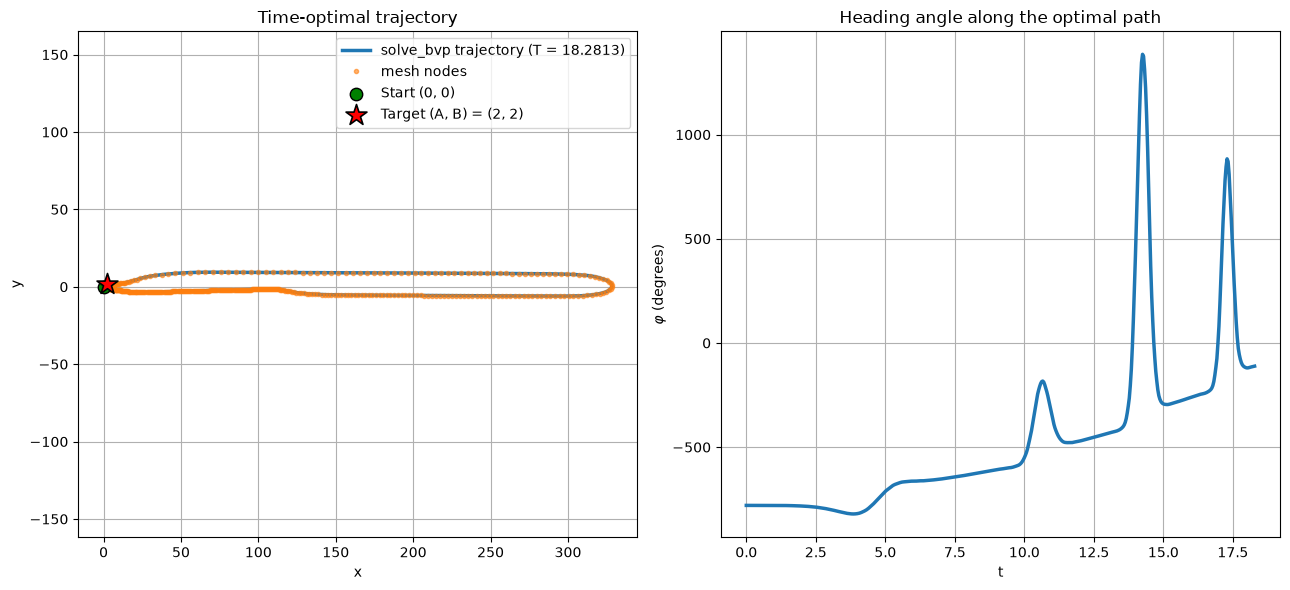

In [3]:
import matplotlib.pyplot as plt

# ---- Extract the solution ----
T_sol = sol.p[0]
print(f"converged: {sol.status == 0} | T = {T_sol:.6f} | "
      f"phi(0) = {np.degrees(sol.y[2, 0]):.3f} deg | mesh nodes = {sol.x.size}")

# Evaluate the continuous solution on a fine grid in s, convert to physical time
s_fine = np.linspace(0, 1, 500)
x_fine, y_fine, phi_fine = sol.sol(s_fine)
t_fine = T_sol * s_fine

# ---- Plot ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))

# Left: trajectory in the (x, y) plane
ax1.plot(x_fine, y_fine, lw=2.5, label=f"solve_bvp trajectory (T = {T_sol:.4f})")
ax1.plot(sol.y[0], sol.y[1], "o", ms=3, alpha=0.6, label="mesh nodes")
ax1.scatter([0], [0], color="green", s=80, marker="o",
            edgecolor="black", zorder=5, label="Start (0, 0)")
ax1.scatter([A], [B], color="red", s=250, marker="*",
            edgecolor="black", linewidths=1.2, zorder=6,
            label=f"Target (A, B) = ({A:g}, {B:g})")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_title("Time-optimal trajectory")
ax1.set_aspect("equal", adjustable="datalim")
ax1.grid(True)
ax1.legend()

# Right: heading angle as a function of physical time
ax2.plot(t_fine, np.degrees(phi_fine), lw=2.5)
ax2.set_xlabel("t")
ax2.set_ylabel(r"$\varphi$ (degrees)")
ax2.set_title("Heading angle along the optimal path")
ax2.grid(True)

fig.tight_layout()
plt.show()